# 응용 4. 시나리오 9가지로 비교하기

응용 1~3에서는 "직진하다 한 번 선회하는 배" 하나로 세 방법을 비교했어요. 실제 바다의 배는 훨씬 다양하게 움직여요. 지그재그로 피하기도 하고, 항구에서 예인선에 밀려 천천히 돌기도 하고, 부두에 묶여 거의 서 있기도 해요. 보고가 오는 환경도 달라요.

이 노트북에서는 **배의 운동 9가지 × 보고 환경 3가지 = 27가지 경우**에서 세 방법을 비교해요.

| 방법 | 배운 곳 |
|---|---|
| 직선 DR | [응용 1](01_dead_reckoning.ipynb) |
| 칼만 필터 + 직선 | [응용 2](02_kalman_filter.ipynb) |
| EKF + 곡선 | [응용 3](03_extended_kalman_filter.ipynb) |
| 제자리 (0차 외삽) | [개념 1](../01_concepts/01_extrapolation.ipynb)의 참고. 마지막 보고 위치에 그대로 둬요. 비교 기준이에요. |

세 방법의 코드는 응용 1~3과 같은 식을 `methods.py`에 모아 두었고, 시나리오와 보고는 `scenarios.py`가 만들어요.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scenarios as S
import methods as M

plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

def stay(rep):
    """제자리(0차 외삽): 마지막 보고 위치에 그대로 둔다."""
    return lambda k, tau: (rep["e"][k] + 0 * tau, rep["n"][k] + 0 * tau)

METHODS = {"제자리": stay, **M.METHODS}
COLORS = {"제자리": "C7", "직선 DR": "C3", "칼만 필터": "C0", "EKF": "C2"}

## 1. 배의 운동 9가지

| 시나리오 | 움직임 | 무엇을 보려나 |
|---|---|---|
| 직진 | 12노트로 곧게 | 기준 |
| 변침 | 200초에 30초 동안 45° 꺾음 | 짧게 방향을 바꿀 때 |
| 완만한 선회 | 10노트, 5분 동안 천천히 60° | 굽은 수로 |
| 전타 선회 | 15노트에서 키를 끝까지, 3분에 한 바퀴. 속력이 9노트로 떨어짐 | 크고 빠른 선회 |
| 지그재그 | ±20°로 좌우를 번갈아 | 도는 방향이 자꾸 바뀔 때 |
| 저속 선회 | 3노트로 90° 돌며 옆으로 밀림 | 예인선이 미는 항구 안 |
| 계류 | 부두에 묶여 1m쯤 앞뒤로 | 거의 서 있는 배 |
| 묘박 | 닻을 중심으로 90m 떨어져 좌우로 흔들림 | 느리지만 실제로 움직이는 배 |
| 황천 직진 | 곧게 가지만 파도에 선수가 ±6° 흔들림 | 잡음 같은 진짜 움직임 |

아래 그림의 회색 선이 실제 항적, 검은 점이 기본 · Class A 조건의 AIS 보고예요. 칸마다 축 크기가 달라요. 계류는 몇 m, 직진은 2km쯤이에요.

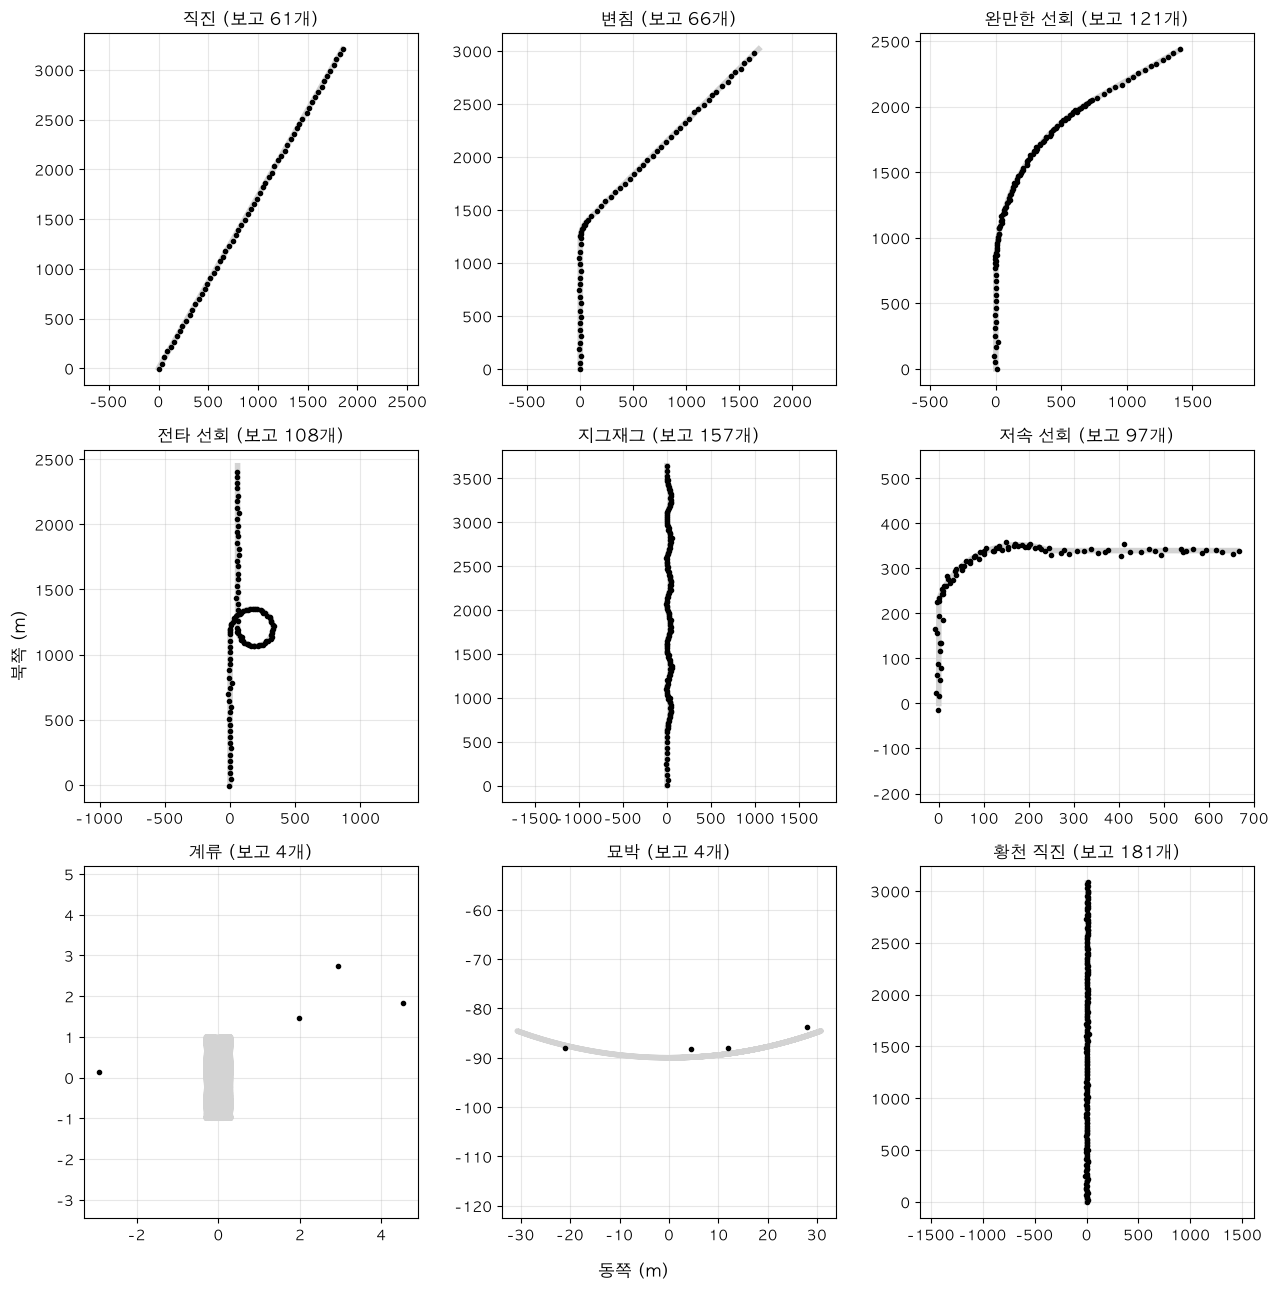

In [2]:
fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for ax, name in zip(axes.flat, S.SCENARIOS):
    tr = S.true_track(name)
    rep = S.make_reports(tr, "기본 · Class A")
    end = int(S.DURATION / S.DT)
    ax.plot(tr["e"][:end], tr["n"][:end], "-", color="lightgray", lw=4)
    ax.plot(rep["e"], rep["n"], "o", color="k", ms=3)
    ax.set_title(f"{name} (보고 {len(rep['t'])}개)")
    ax.set_aspect("equal", adjustable="datalim"); ax.grid(alpha=.3)
fig.supxlabel("동쪽 (m)"); fig.supylabel("북쪽 (m)"); plt.tight_layout(); plt.show()

계류와 묘박은 보고가 4개뿐이에요. 다음에 볼 보고 간격 규칙 때문이에요.

## 2. 보고 환경 3가지

AIS는 배가 빠를수록, 방향을 바꿀수록 자주 보고해요. 국제 표준(ITU-R M.1371)의 간격을 단순하게 옮기면 이래요.

| 배 상태 | Class A | Class B (CS) |
|---|---|---|
| 묘박·계류, 3노트 이하 | 3분 | 3분 (2노트 이하) |
| 14노트 이하 | 10초, 방향을 바꾸는 중이면 3⅓초 | 30초 |
| 14~23노트 | 6초, 방향을 바꾸는 중이면 2초 | 30초 |
| 23노트 초과 | 2초 | 30초 |

Class A는 큰 상선, Class B는 레저 보트 같은 소형선이 주로 써요. 여기서는 진행 방향이 초당 0.1° 이상 돌면 "방향을 바꾸는 중"으로 봤어요.

| 조건 | 보고 간격 | 위치 잡음 | 그 밖 |
|---|---|---|---|
| 기본 · Class A | Class A | 5m | |
| 열악 · Class A | Class A | 10m | 보고 20%가 빠지고(손실), 3%는 위치가 300m 튐(이상치) |
| 기본 · Class B | Class B | 5m | |

세 조건 모두 SOG에 0.2노트, COG에 `2° + 5°/SOG` 정도의 잡음을 넣었어요. **느릴수록 COG가 많이 흔들려요.** GPS 위치가 조금만 흔들려도 느린 배는 진행 방향이 크게 바뀐 것처럼 보이기 때문이에요. 서 있는 배의 COG는 거의 아무 방향이나 가리켜요.

In [3]:
print(f"{'시나리오':8s}" + "".join(f"{c:>14s}" for c in S.CONDITIONS))
for name in S.SCENARIOS:
    tr = S.true_track(name)
    counts = [len(S.make_reports(tr, c)["t"]) for c in S.CONDITIONS]
    print(f"{name:8s}" + "".join(f"{n:>14d}" for n in counts))

시나리오      기본 · Class A  열악 · Class A  기본 · Class B
직진                  61            50            21
변침                  66            54            21
완만한 선회             121            99            21
전타 선회              108            88            21
지그재그               157           129            21
저속 선회               97            78            21
계류                   4             3             4
묘박                   4             3             4
황천 직진              181           152            21


10분 동안 받은 보고 개수예요. Class B는 이동 중인 배도 30초마다라서 21개뿐이에요. 보고 사이에 30초를 외삽으로 버텨야 해요.

## 3. 한 번 돌려 보기: 기본 · Class B

보고 간격이 길어야 방법 사이의 차이가 눈에 보여요. 응용 1~3처럼 보고마다 다음 보고 전까지 외삽한 선을 끊어서 그렸어요.

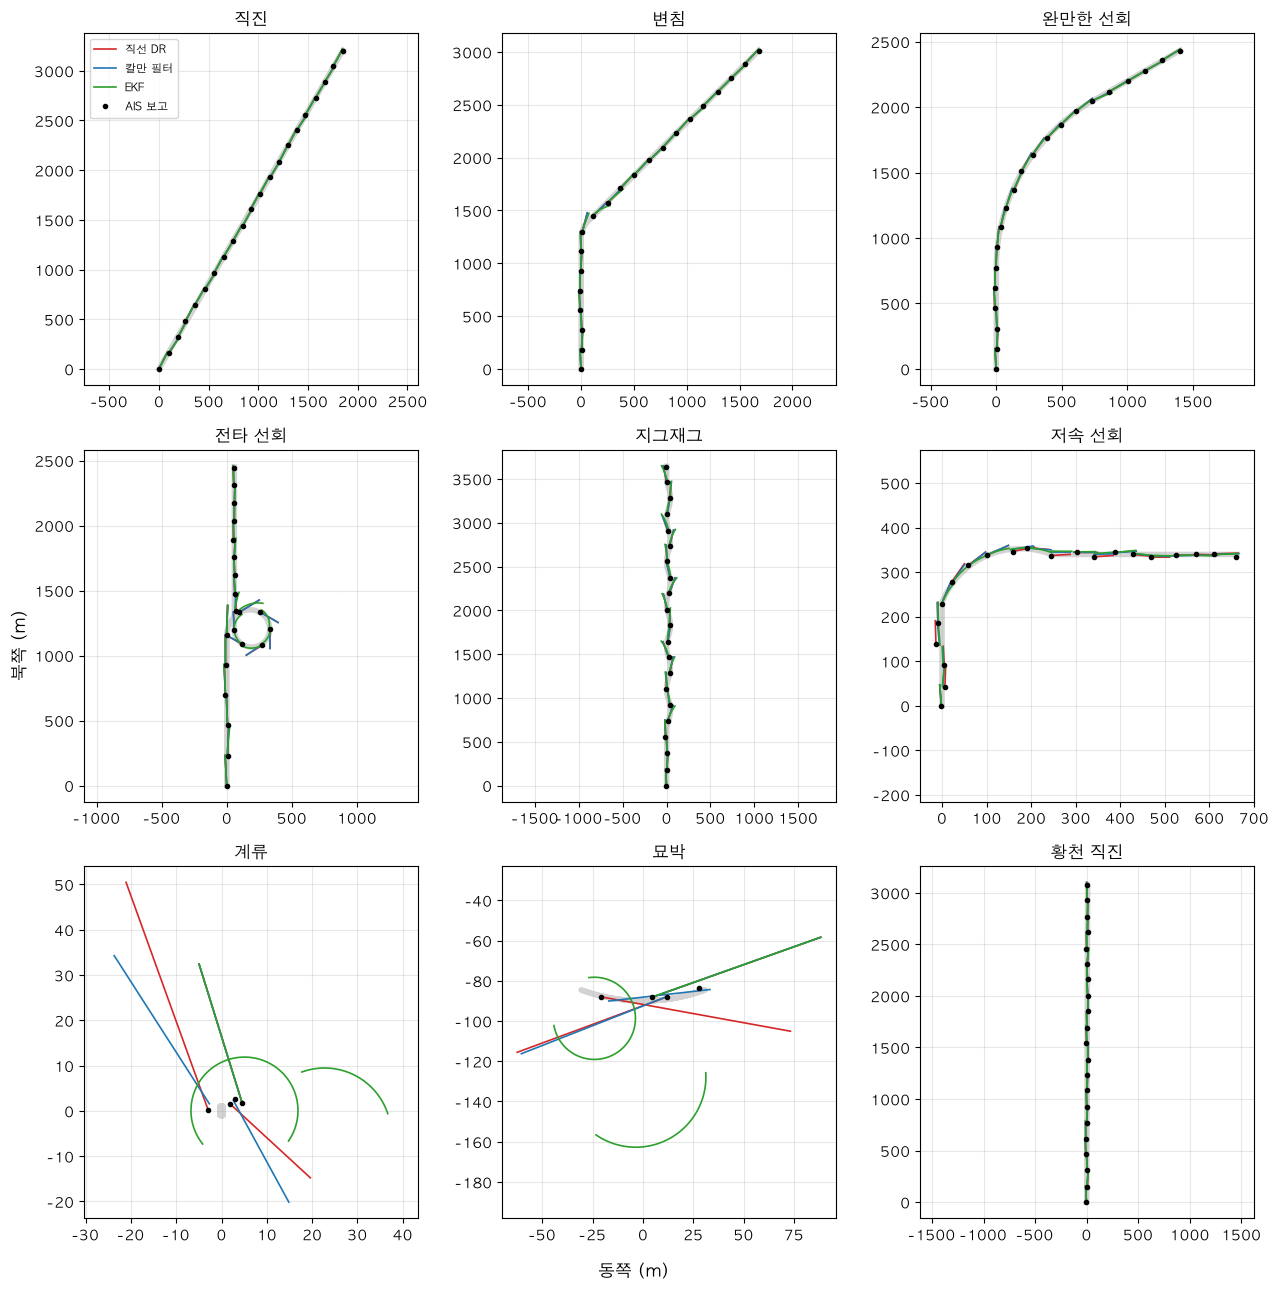

In [4]:
cond = "기본 · Class B"
fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for ax, name in zip(axes.flat, S.SCENARIOS):
    tr = S.true_track(name)
    rep = S.make_reports(tr, cond)
    end = int(S.DURATION / S.DT)
    ax.plot(tr["e"][:end], tr["n"][:end], "-", color="lightgray", lw=4, zorder=0)
    for m in ["직선 DR", "칼만 필터", "EKF"]:
        predict = METHODS[m](rep)
        for k in range(len(rep["t"]) - 1):
            pe, pn = predict(k, np.arange(0, rep["t"][k + 1] - rep["t"][k] + 0.5, 0.5))
            ax.plot(pe, pn, "-", color=COLORS[m], lw=1.2, label=m if k == 0 else None)
    ax.plot(rep["e"], rep["n"], "o", color="k", ms=3, label="AIS 보고")
    ax.set_title(name); ax.set_aspect("equal", adjustable="datalim"); ax.grid(alpha=.3)
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.supxlabel("동쪽 (m)"); fig.supylabel("북쪽 (m)"); plt.tight_layout(); plt.show()

볼 곳은 세 칸이에요.

- **전타 선회**: 선이 원 바깥으로 튀어 나가요. 직선 두 방법은 접선 방향으로, EKF는 원을 따라가려 해요.
- **지그재그**: 그림으로는 작게 보이지만, EKF 선이 방향이 바뀌는 곳에서 원래 돌던 쪽으로 계속 휘어 나가요.
- **계류·묘박**: 3분 동안 흔들리는 COG 방향으로 밀어서, 서 있는 배가 엉뚱한 곳으로 가는 선이 그려져요.

## 4. 27가지 경우 모두 비교

그림 한 장은 잡음 한 번의 결과라 우연이 섞여요. 그래서 경우마다 잡음을 20번 바꿔(시드 1~20) 돌리고 오차를 모았어요.

- **평균**: 보통 얼마나 틀리나
- **p95**: 가끔 크게 틀릴 때. 오차를 작은 순으로 세웠을 때 95% 위치의 값

In [5]:
SEEDS = range(1, 21)

def compare(cond):
    """시나리오마다 방법별 오차(평균, p95)를 모은다."""
    table = {}
    for name in S.SCENARIOS:
        tr = S.true_track(name)
        errs = {m: [] for m in METHODS}
        for seed in SEEDS:
            rep = S.make_reports(tr, cond, seed=seed)
            for m, f in METHODS.items():
                errs[m].append(S.errors(tr, rep, f(rep)))
        table[name] = {m: (np.mean(np.concatenate(v)), np.percentile(np.concatenate(v), 95)) for m, v in errs.items()}
    return table

results = {cond: compare(cond) for cond in S.CONDITIONS}

for cond, table in results.items():
    print(f"■ {cond}    평균 오차 m (p95)")
    print(f"{'시나리오':8s}" + "".join(f"{m:>16s}" for m in METHODS) + "    가장 작음")
    for name, row in table.items():
        best = min(row, key=lambda m: row[m][0])
        print(f"{name:8s}" + "".join(f"{row[m][0]:9.1f} ({row[m][1]:5.1f})" for m in METHODS) + f"    {best}")
    print()

■ 기본 · Class A    평균 오차 m (p95)
시나리오                 제자리           직선 DR           칼만 필터             EKF    가장 작음
직진           29.1 ( 57.1)      6.3 ( 12.6)      4.0 (  8.2)      3.7 (  7.7)    EKF
변침           28.1 ( 56.6)      6.4 ( 12.8)      3.9 (  8.2)      3.7 (  8.0)    EKF
완만한 선회       17.0 ( 43.9)      6.3 ( 12.3)      3.0 (  6.4)      2.8 (  6.2)    EKF
전타 선회        18.1 ( 41.5)      6.4 ( 12.6)      3.1 (  6.6)      3.1 (  6.7)    칼만 필터
지그재그         14.8 ( 41.4)      6.3 ( 12.5)      2.8 (  6.0)      3.7 (  6.7)    칼만 필터
저속 선회         8.6 ( 17.8)      6.3 ( 12.5)      2.7 (  5.6)      2.7 (  5.4)    EKF
계류            6.6 ( 13.1)     15.8 ( 39.3)     15.1 ( 39.6)     20.1 ( 44.6)    제자리
묘박           28.5 ( 50.2)     20.7 ( 60.7)     20.1 ( 57.1)     42.1 ( 82.8)    칼만 필터
황천 직진        10.5 ( 20.8)      6.3 ( 12.3)      2.3 (  4.6)      2.3 (  4.5)    EKF

■ 열악 · Class A    평균 오차 m (p95)
시나리오                 제자리           직선 DR           칼만 필터             EKF    가장 작음
직진       

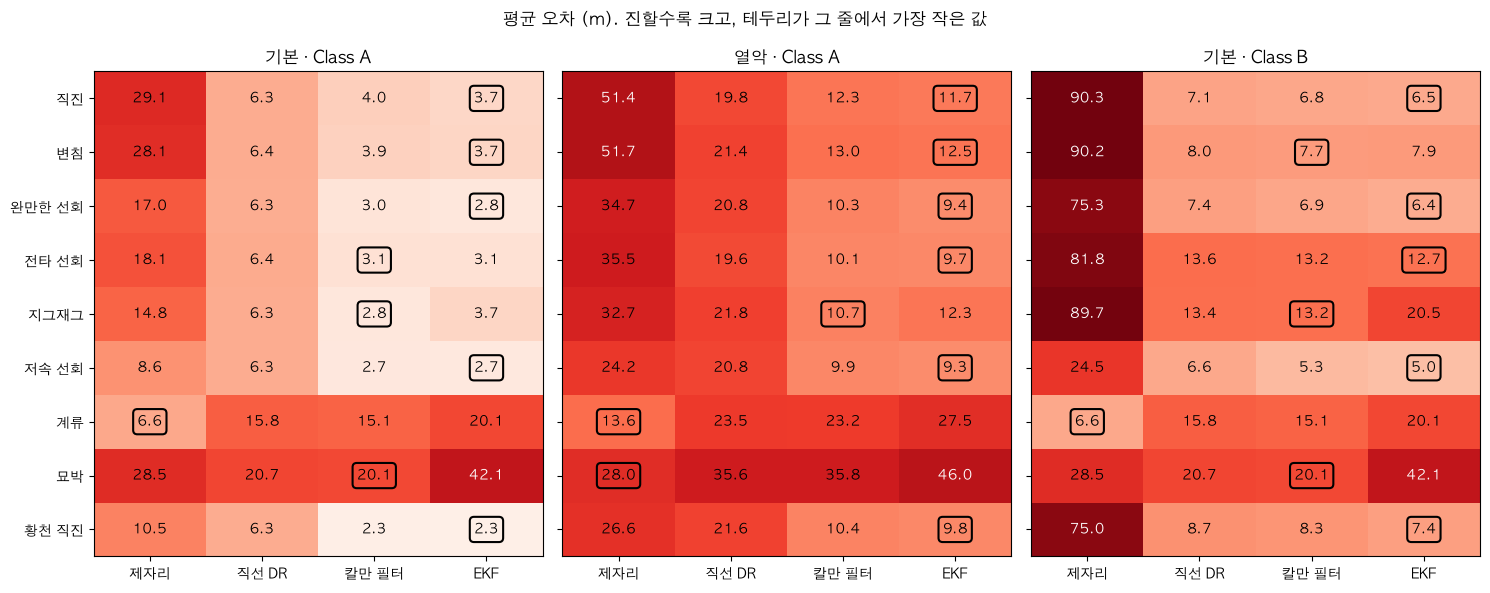

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
names, ms = list(S.SCENARIOS), list(METHODS)
for ax, (cond, table) in zip(axes, results.items()):
    grid = np.array([[table[n][m][0] for m in ms] for n in names])
    ax.imshow(np.log(grid), cmap="Reds", aspect="auto", vmin=np.log(2), vmax=np.log(100))
    for i in range(len(names)):
        best = grid[i].argmin()
        for j in range(len(ms)):
            ax.text(j, i, f"{grid[i, j]:.1f}", ha="center", va="center",
                    color="w" if grid[i, j] > 40 else "k",
                    bbox=dict(boxstyle="round", fc="none", ec="k", lw=1.5) if j == best else None)
    ax.set_xticks(range(len(ms)), ms); ax.set_yticks(range(len(names)), names); ax.set_title(cond)
fig.suptitle("평균 오차 (m). 진할수록 크고, 테두리가 그 줄에서 가장 작은 값"); plt.tight_layout(); plt.show()

## 5. 결과 읽기

### 기본 · Class A: 보고가 잦으면 다 잘 맞아요

이동 중인 배는 직선 DR도 평균 6m 남짓이에요. 이 오차는 대부분 보고 위치 자체의 잡음(5m)이에요. 3~10초 사이에는 배가 멀리 못 가서, 직선이든 곡선이든 크게 다르지 않아요. 칼만 필터와 EKF는 여러 보고를 섞어 잡음을 줄여서 평균 3~4m로 절반쯤이에요. 둘의 차이는 거의 없어요.

### 기본 · Class B: 간격이 길면 모델 가정의 차이가 드러나요

- **직진, 완만한 선회**: 셋 다 7m 안팎으로 비슷해요.
- **전타 선회**: 셋 다 평균 13m, p95 50m 안팎으로 커져요. 30초면 원의 1/6을 도는데, 그 사이를 외삽해야 하기 때문이에요. EKF가 조금 나아요.
- **지그재그**: **EKF가 가장 나빠요**(직선 DR 13.4m, EKF 20.5m). EKF는 "지금 도는 속도로 계속 돈다"고 가정해요. 30초 사이에 도는 방향이 바뀌면, 직선보다 더 반대쪽으로 빗나가요. 응용 3에서 선회 한 번에는 EKF가 가장 좋았던 것과 반대예요.

### 계류·묘박: 서 있는 배에는 제자리가 나아요

- **계류**: 제자리가 6.6m로 가장 좋고, 나머지 셋은 15~20m예요. 보고가 3분마다 오는데, 크게 흔들리는 COG 방향으로 작은 SOG를 3분 동안 밀어서예요. 0.2노트 잡음도 3분이면 18m예요.
- **묘박**: EKF가 42m로 가장 나빠요. 흔들리는 COG를 "돌고 있다"로 읽어 도는 속도까지 틀리게 추정하기 때문이에요. 배가 실제로 원호를 그리며 움직이니 제자리도 28m로 완벽하진 않아요.

개념 1에서 0차 외삽(마지막 값 유지)은 짧은 참고로만 다뤘어요. 바로 이런 곳에서 필요해요.

### 열악 · Class A: 필터는 이상치에 약해요

평균만 보면 칼만 필터와 EKF가 직선 DR의 절반이에요. 그런데 **p95는 필터가 더 나빠요**(직진에서 직선 DR 26.8m, 칼만 필터 52.1m, EKF 42.0m). 직선 DR은 300m 튄 보고 하나만 틀리고 다음 보고에서 바로 돌아와요. 필터는 튄 위치를 측정으로 받아들여 속도까지 틀리게 고치고, 그 틀린 속도로 다음 몇 번의 보고 동안 계속 밀어요.

## 6. 정리

| 상황 | 잘 맞는 방법 | 이유 |
|---|---|---|
| 보고가 잦음 (Class A) | 칼만 필터·EKF | 잡음을 줄임. 직선과 곡선의 차이는 작음 |
| 간격이 길고 꾸준히 돎 | EKF | 원을 따라 외삽 |
| 간격이 길고 도는 방향이 자주 바뀜 | 직선 DR·칼만 필터 | "계속 돈다"는 가정이 틀림 |
| 거의 서 있음 | 제자리 | 느리면 COG가 믿을 수 없음 |
| 위치가 가끔 크게 튐 | (지금 방법으로는 없음) | 이상치를 걸러야 함 |

**모든 경우에 이기는 방법은 없어요.** 실제로 쓸 방법은 한 가지 모델이 아니라, 상황에 따라 고르거나 섞는 쪽이 돼요. 다음에 해 볼 만한 개선이에요.

- **정지 판단**: SOG가 아주 작으면 제자리로 둬요.
- **이상치 거르기**: 칼만 필터가 예측한 위치와 너무 먼 보고는 받아들이지 않아요.
- **도는 속도 줄이기**: EKF로 외삽할 때 시간이 지날수록 도는 속도를 0 쪽으로 줄여, 지그재그에서 덜 빗나가게 해요.

이 시뮬레이션은 공부용으로 단순하게 만들었어요. 배의 크기와 속력은 시나리오마다 하나로 고정했고, 보고가 늦게 도착하는 수신 지연은 넣지 않았어요.

## 직접 해 보기

- `methods.ekf_ctrv(rep, q_turn=...)`의 `q_turn`을 키우거나 줄여서 지그재그와 전타 선회가 어떻게 바뀌는지 보세요.
- `stay`와 `M.dead_reckoning`을 섞어, SOG가 1노트보다 작으면 제자리로 두는 방법을 만들어 `METHODS`에 넣어 보세요.

In [7]:
# 여기서 직접 바꿔 보세요